# Lab 5 Task 3: Automatic OFDM Receiver

Complete the CFO, channel-estimation, equalizer-floor, and pilot-phase equations. Then exercise the frozen receiver on a deterministic impaired capture and a 100-trial Monte Carlo study


In [2]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Receiver equations


<span style="color:#165696"><b>Report.</b> Derive the CFO estimator and its ambiguity interval. </span>

The CFO estimator uses the phase rotation between repeated sections of the short preamble. The correlation $P[d]=\sum r^*[d+n]\,r[d+n+L]$ contains a phase term $e^{j2\pi\Delta fL/f_s}$ due to the carrier frequency offset. Taking the angle of $P[d]$ gives $\hat{\Delta f}=\frac{f_s}{2\pi L}\angle P[\hat d]$. For the example $f_s=1\ \text{MHz}$, $L=16$, and $\angle P=0.4$ rad, $\hat{\Delta f}=\frac{1{,}000{,}000}{2\pi(16)}(0.4)\approx 3.98\ \text{kHz}$. Because the measured phase is limited to $[-\pi,\pi)$, the ambiguity interval is $\Delta f\in\left[-\frac{f_s}{2L},\frac{f_s}{2L}\right)$ which gives $\Delta f\in[-31.25,\ 31.25)\ \text{kHz}$ for $f_s=1$ MHz and $L=16$.

In [3]:
sample_rate_sps = 1_000_000
repeat_length = 16
p_value = np.exp(1j*0.4)

# CFO ambiguity range: ±fs/(2L)
cfo_ambiguity_hz = sample_rate_sps / (2 * repeat_length)

# CFO estimate: fs/(2πL) * angle(P)
cfo_estimate_hz = sample_rate_sps / (2 * np.pi * repeat_length) * np.angle(p_value)

known_training = np.ones((2, 52), dtype=complex)
true_channel = np.linspace(0.4, 1.2, 52) * np.exp(1j * np.linspace(-0.5, 0.7, 52))
received_training = known_training * true_channel

# Two-symbol LS estimate
channel_estimate = np.mean(received_training / known_training, axis=0)

# Relative ZF floor
zf_floor = 0.05 * np.median(np.abs(channel_estimate))

known_pilots = np.array([1, 1, 1, -1], dtype=complex)
equalized_pilots = known_pilots * np.exp(1j * 0.2)

# Common phase error estimate
cpe_rad = np.angle(np.sum(np.conj(known_pilots) * equalized_pilots))

print("CFO ambiguity limit (Hz):", cfo_ambiguity_hz)
print("example CFO estimate (Hz):", cfo_estimate_hz)
print("channel-estimation maximum error:", np.max(np.abs(channel_estimate - true_channel)))
print("relative ZF floor:", zf_floor)
print("pilot CPE (rad):", cpe_rad)

CFO ambiguity limit (Hz): 31250.0
example CFO estimate (Hz): 3978.8735772973837
channel-estimation maximum error: 0.0
relative ZF floor: 0.04000000000000001
pilot CPE (rad): 0.2


In [4]:
assert cfo_ambiguity_hz == 31_250
assert np.max(np.abs(channel_estimate-true_channel)) < 1e-12
assert np.isclose(cpe_rad, 0.2)
print("Receiver-equation checks passed.")


Receiver-equation checks passed.


## Synthetic acquisition and Monte Carlo


<span style="color:#165696"><b>Report.</b> Report detection, timing, CFO RMSE, BER, PER, EVM, and every failure mode from the 100 trials. </span>

No acquisition failures or timing failures were observed over the 100 trials, resulting in a 100% detection rate and 100% timing-within-one-sample rate. The only observed failures were two CRC packet failures, producing a PER of 2.0%, while the overall BER remained low at $1.04\times10^{-5}$. The remaining metrics were output below.

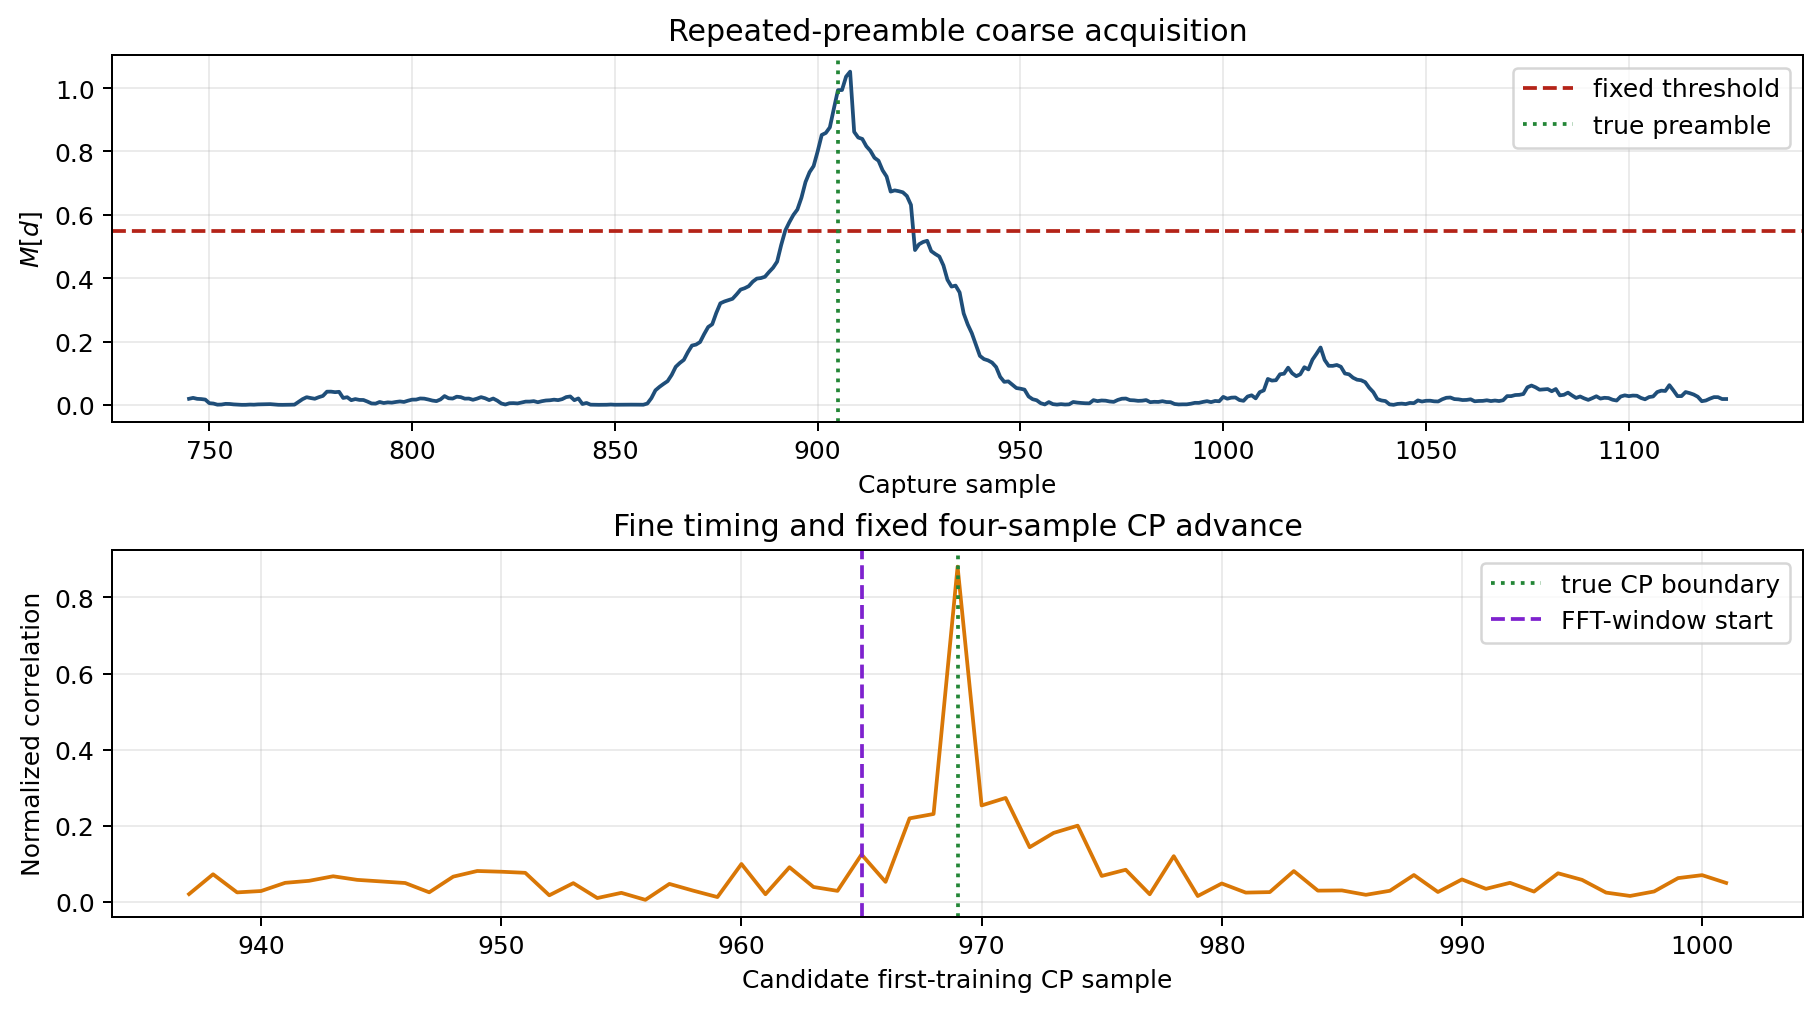

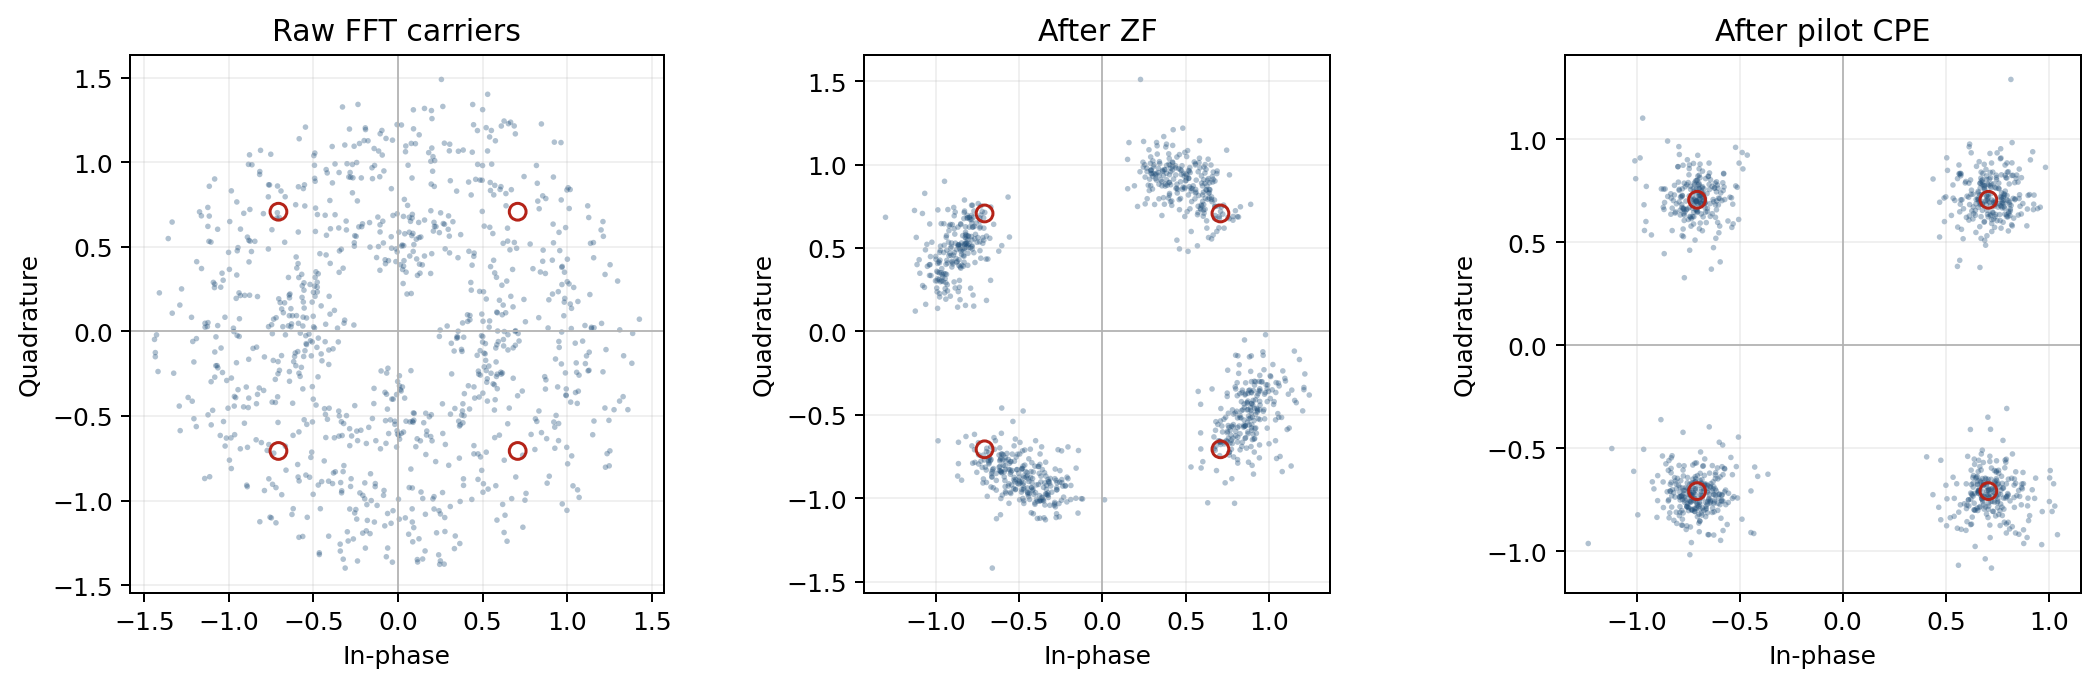

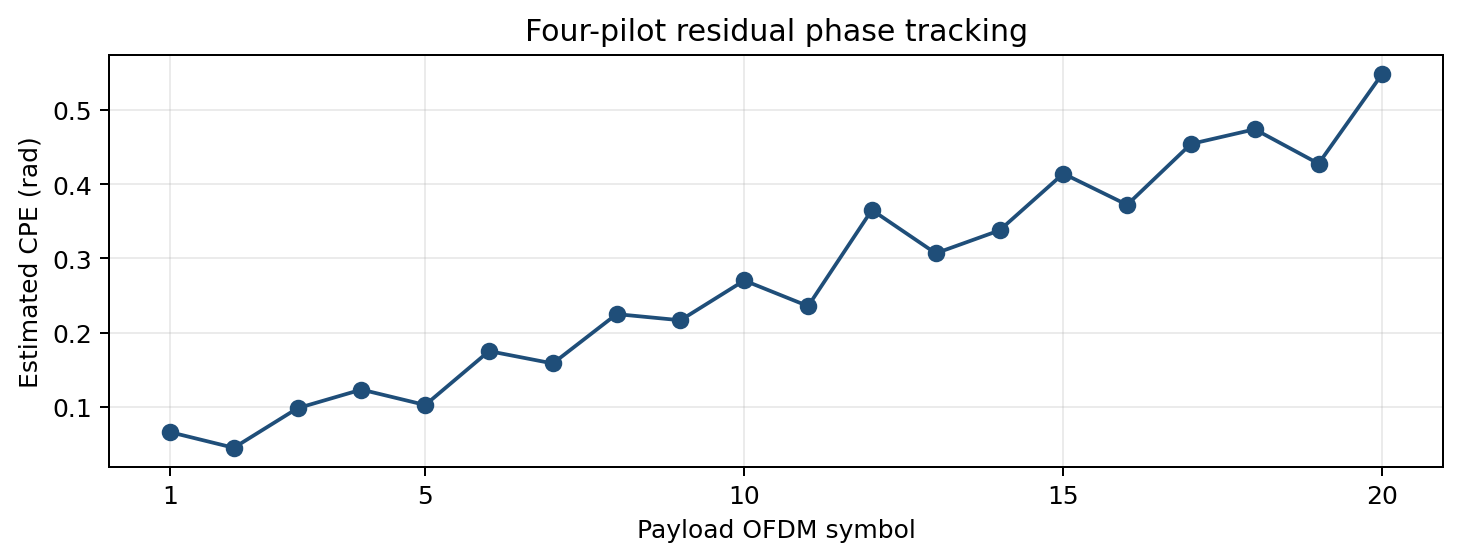

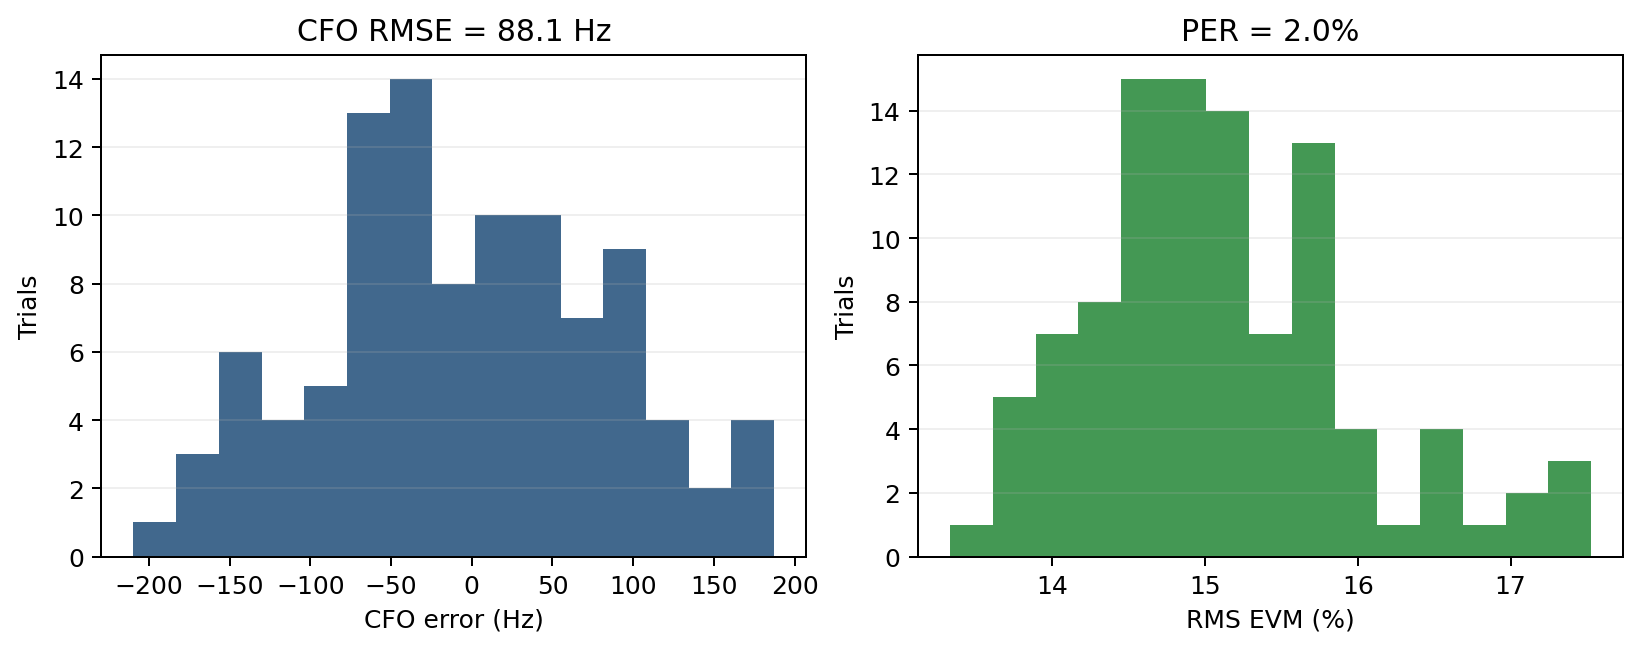

fixed case: {
  "true_cfo_hz": 7500.0,
  "estimated_cfo_hz": 7448.986521864943,
  "cfo_error_hz": -51.013478135057085,
  "timing_error_samples": 0,
  "ber": 0.0,
  "evm_rms": 0.15006152062060268,
  "crc_ok": true
}
Monte Carlo: {
  "trials": 100,
  "detected": 100,
  "detection_rate": 1.0,
  "timing_within_one_rate": 1.0,
  "cfo_rmse_hz": 88.14839886452513,
  "ber": 1.0416666666666666e-05,
  "packet_error_rate": 0.020000000000000018,
  "mean_evm_rms": 0.1511880996510483
}


In [5]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task3_synthetic_acquisition', 'task3_synthetic_constellations', 'task3_pilot_cpe', 'task3_monte_carlo'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))

print("fixed case:", json.dumps(simulation["synthetic_acquisition"], indent=2))
print("Monte Carlo:", json.dumps(simulation["monte_carlo"], indent=2))


## Report work

<span style="color:#165696"><b>Report.</b> Explain the coarse repeated-field metric and the fine training correlation. </span>

The coarse repeated-field metric exploits the 16-sample repetition in the short preamble. It computes the normalized correlation $M[d]=\frac{|P[d]|^2}{R[d]^2+\epsilon}$, which produces a strong peak when two adjacent repeated sections align, providing a coarse estimate of the frame start and the CFO phase rotation. In the measured result, the acquisition peak exceeds the 0.55 threshold and occurs near the true preamble location, indicating successful frame detection.

After CFO correction, fine timing is performed by cross-correlating with the known two-symbol training sequence within $\pm 32$ samples of the coarse estimate. Because the training symbols are known exactly, the correlation produces a sharp peak at the correct CP boundary, allowing accurate FFT-window placement before channel estimation and equalization. The FFT window is then intentionally advanced by four samples into the cyclic prefix, leaving 12 CP samples for channel settling rather than representing a timing error.

<span style="color:#165696"><b>Report.</b> Explain the four-sample FFT-window advance into the cyclic prefix. </span>

The fine timing estimate identifies the first-training CP boundary, but the FFT window is intentionally started 4 samples earlier, inside the cyclic prefix. Since the CP length is 16 samples, this leaves 12 CP samples before the useful symbol begins, providing margin for channel transients and timing uncertainty. Because the cyclic prefix is a copy of the end of the symbol, starting the FFT window anywhere within the CP preserves the circular-convolution model and does not introduce distortion. Therefore, the 4-sample advance is a deliberate design choice rather than a timing error.

<span style="color:#165696"><b>Report.</b> Distinguish full-band training from the four payload pilots. </span>

The full-band training symbols are used once at the start of the frame to estimate $\hat H[k]$ on all active subcarriers for equalization. This is visible when comparing the "Raw FFT carriers" and "After ZF" constellations, where the distorted ring-shaped constellation is transformed into four distinct QPSK clusters.

The four payload pilots are then used to estimate and correct the residual common phase error (CPE) in each OFDM symbol. Comparing the "After ZF" and "After pilot CPE" constellations shows that the pilots remove the remaining constellation rotation and tighten the clusters around the ideal QPSK locations. The CPE plot shows that the required phase correction varies across the packet, demonstrating continuous pilot-based tracking of residual phase drift.